# 02 — Data drift (Evidently, Jensen–Shannon)

Compares two scenarios on the EKS cluster, from the committed evidence files:
- `stable`: the first N days vs. the rest (no deliberate change);
- `channel_shift`: the first N days vs. only one sales Channel after the reference cutoff (the order mix shifts onto one marketplace).

Sources: [`drift-summary-eks.json`](../docs/evidence/aws/drift-summary-eks.json) (re-run on Nov 4) and
[`mle-drift-20261031.json`](../docs/evidence/aws/mle-drift-20261031.json) (first run on Oct 31).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EVIDENCE = ROOT / "docs" / "evidence"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
runs = {
    "Nov 4": json.loads((EVIDENCE / "aws" / "drift-summary-eks.json").read_text()),
    "Oct 31": json.loads((EVIDENCE / "aws" / "mle-drift-20261031.json").read_text()),
}
records = [
    {
        "run": day,
        "scenario": scenario,
        "column": col,
        **info,
        "reference rows": data[scenario]["reference_rows"],
        "current rows": data[scenario]["current_rows"],
    }
    for day, data in runs.items()
    for scenario in data
    for col, info in data[scenario]["columns"].items()
]
df = pd.DataFrame(records)
df[
    [
        "run",
        "scenario",
        "column",
        "score",
        "threshold",
        "drift",
        "reference rows",
        "current rows",
    ]
]

,run,scenario,column,score,threshold,drift,reference rows,current rows
0,Nov 4,stable,seller_sku,0.066418,0.2,False,72109,287348
1,Nov 4,stable,label,0.000776,0.1,False,72109,287348
2,Nov 4,channel_shift,seller_sku,0.202800,0.2,True,72109,8320
3,Nov 4,channel_shift,label,0.029788,0.1,False,72109,8320
4,Oct 31,stable,seller_sku,0.066418,0.2,False,72109,287348
5,Oct 31,stable,label,0.000776,0.1,False,72109,287348
6,Oct 31,channel_shift,seller_sku,0.202800,0.2,True,72109,8320
7,Oct 31,channel_shift,label,0.029788,0.1,False,72109,8320


## Do the two runs give the same result?

In [3]:
a = df[df["run"] == "Nov 4"].set_index(["scenario", "column"])
b = df[df["run"] == "Oct 31"].set_index(["scenario", "column"])
diff = (a["score"] - b["score"]).abs()
print("largest score difference between the two runs:", f"{diff.max():.2e}")
assert diff.max() < 1e-9 and (a["drift"] == b["drift"]).all(), "the two runs must match"

largest score difference between the two runs: 2.78e-17


The two runs match up to rounding error, as expected since they use the same source data: this result is **reproducible** across two cluster bring-ups.

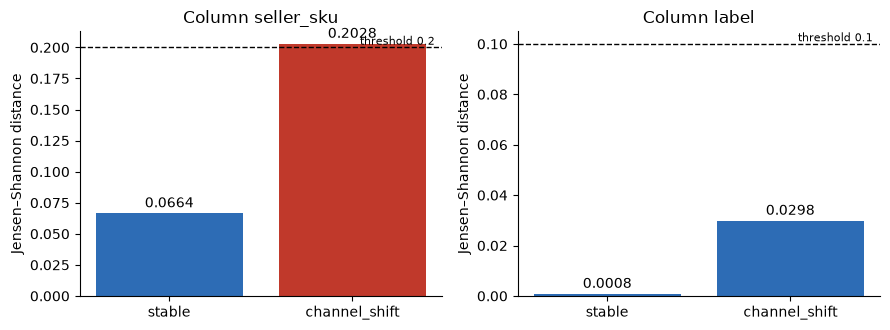

In [4]:
view = df[df["run"] == "Nov 4"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, col in zip(axes, ["seller_sku", "label"]):
    sub = view[view["column"] == col].set_index("scenario")
    colors = ["#c0392b" if d else "#2d6cb5" for d in sub["drift"]]
    bars = ax.bar(sub.index, sub["score"], color=colors)
    ax.bar_label(bars, fmt="%.4f", padding=2)
    ax.axhline(sub["threshold"].iloc[0], color="black", ls="--", lw=1)
    ax.text(
        0.98,
        sub["threshold"].iloc[0],
        f" threshold {sub['threshold'].iloc[0]}",
        ha="right",
        va="bottom",
        transform=ax.get_yaxis_transform(),
        fontsize=8,
    )
    ax.set_title(f"Column {col}")
    ax.set_ylabel("Jensen–Shannon distance")
plt.tight_layout()
plt.show()

In [5]:
shift = view[(view["scenario"] == "channel_shift") & (view["column"] == "seller_sku")].iloc[0]
margin = shift["score"] - shift["threshold"]
print(
    f"channel_shift / seller_sku: {shift['score']:.4f} vs. threshold {shift['threshold']} -> exceeds by {margin:.4f} ({margin / shift['threshold']:.1%})"
)
stable = view[(view["scenario"] == "stable") & (view["column"] == "seller_sku")].iloc[0]
print(
    f"stable / seller_sku       : {stable['score']:.4f} -> {stable['threshold'] - stable['score']:.4f} below threshold"
)

channel_shift / seller_sku: 0.2028 vs. threshold 0.2 -> exceeds by 0.0028 (1.4%)
stable / seller_sku       : 0.0664 -> 0.1336 below threshold


**Reading the results.** The stable scenario does not alert (0.066 vs. a threshold of 0.2) and the `label` column is unchanged in both. The Channel shift is flagged on `seller_sku`,
but only **exceeds the threshold by about 1.4%**: a score of 0.2028 vs. 0.2. The detector works, but this case sits right at the threshold,
so a run on a different batch could fall below it. With real data, the threshold should be set from the score distribution of many "stable" pairs
instead of using a fixed value.